Cell 1 — Imports & Setup


In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROCESSED_DIR = Path('../data/processed')
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

Cell 2 — Load Cleaned Data (from Week 3)


In [34]:
ratings = pd.read_csv(PROCESSED_DIR / 'ratings_clean.csv', parse_dates=['timestamp'])
movies = pd.read_csv(PROCESSED_DIR / 'movies_clean.csv')

print(f"Ratings: {ratings.shape}")
print(f"Movies : {movies.shape}")
display(ratings.head())
display(movies.head())

Ratings: (101696, 7)
Movies : (6685, 4)


,userId,movieId,rating,timestamp,year,month,is_reliable_movie
0,1,16,4.0,2008-08-05 00:56:33,2008,8,True
1,1,24,1.5,2008-08-05 00:23:27,2008,8,True
2,1,32,4.0,2008-08-05 00:30:46,2008,8,True
3,1,47,4.0,2008-08-05 00:35:56,2008,8,True
4,1,50,4.0,2008-08-05 00:35:23,2008,8,True


,movieId,title,genres,is_reliable
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,True
1,2,Jumanji (1995),Adventure|Children|Fantasy,True
2,3,Grumpier Old Men (1995),Comedy|Romance,True
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,True
4,5,Father of the Bride Part II (1995),Comedy,True


Cell 3 — EDA: Distribution of Ratings


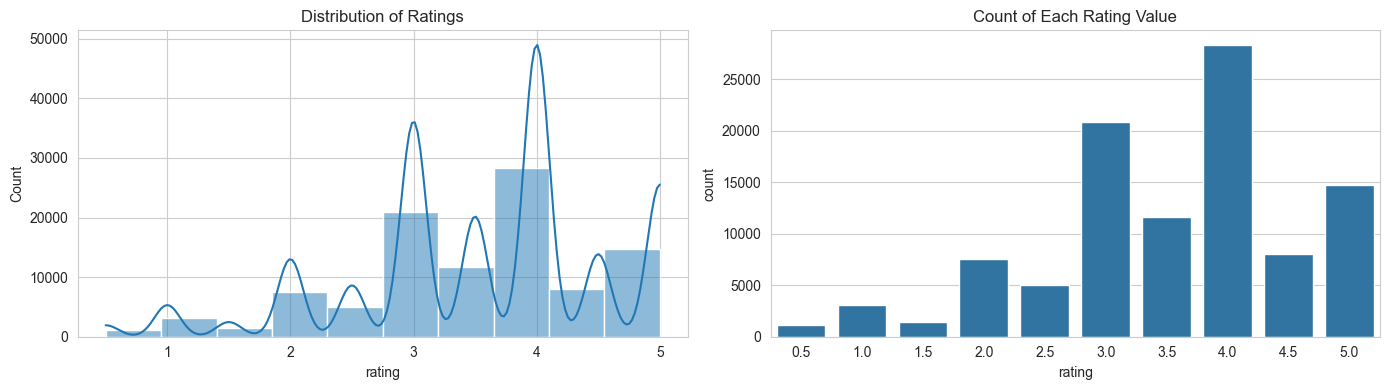

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(ratings['rating'], bins=10, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Ratings')

sns.countplot(x='rating', data=ratings, ax=axes[1])
axes[1].set_title('Count of Each Rating Value')

plt.tight_layout()
plt.show()

Cell 4 — EDA: Ratings per User & per Movie


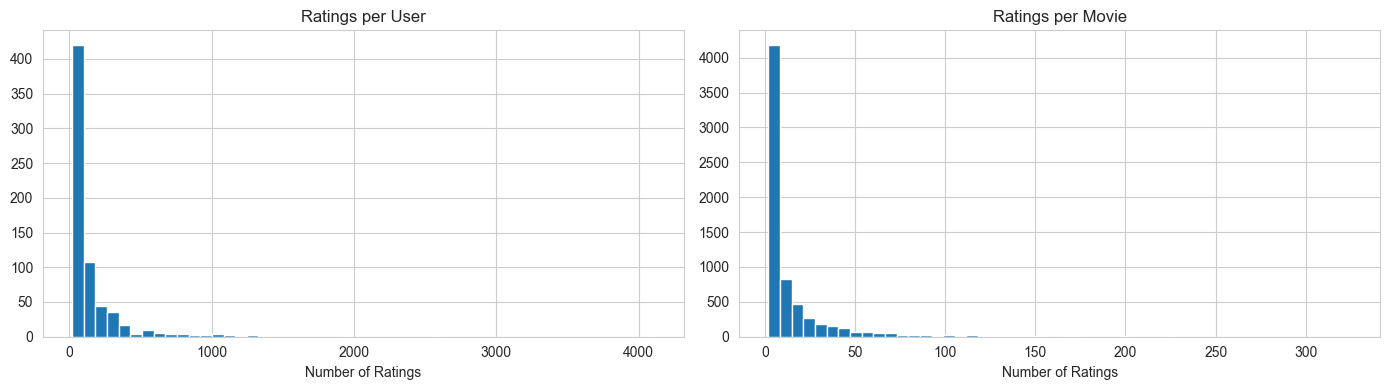

In [36]:
user_counts = ratings['userId'].value_counts()
movie_counts = ratings['movieId'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(user_counts, bins=50)
axes[0].set_title('Ratings per User')
axes[0].set_xlabel('Number of Ratings')

axes[1].hist(movie_counts, bins=50)
axes[1].set_title('Ratings per Movie')
axes[1].set_xlabel('Number of Ratings')

plt.tight_layout()
plt.show()

Cell 5 — EDA: Ratings Over Time


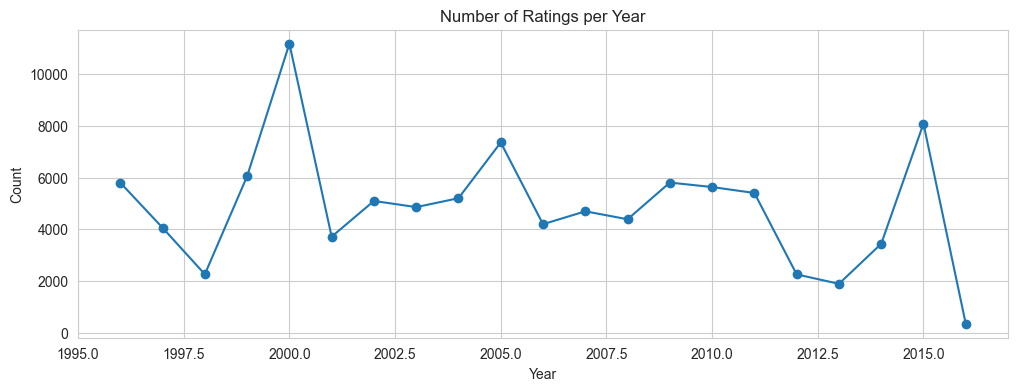

In [37]:
ratings_by_year = ratings.groupby('year').size()

plt.figure(figsize=(12, 4))
ratings_by_year.plot(kind='line', marker='o')
plt.title('Number of Ratings per Year')
plt.xlabel('Year')
plt.ylabel('Count')
plt.show()

Cell 6  — EDA: Rating Balance Check


RATING BALANCE CHECK (Target Imbalance)
        count  percentage
rating                   
0.5      1113        1.09
1.0      3067        3.02
1.5      1420        1.40
2.0      7524        7.40
2.5      4981        4.90
3.0     20876       20.53
3.5     11658       11.46
4.0     28306       27.83
4.5      8006        7.87
5.0     14745       14.50


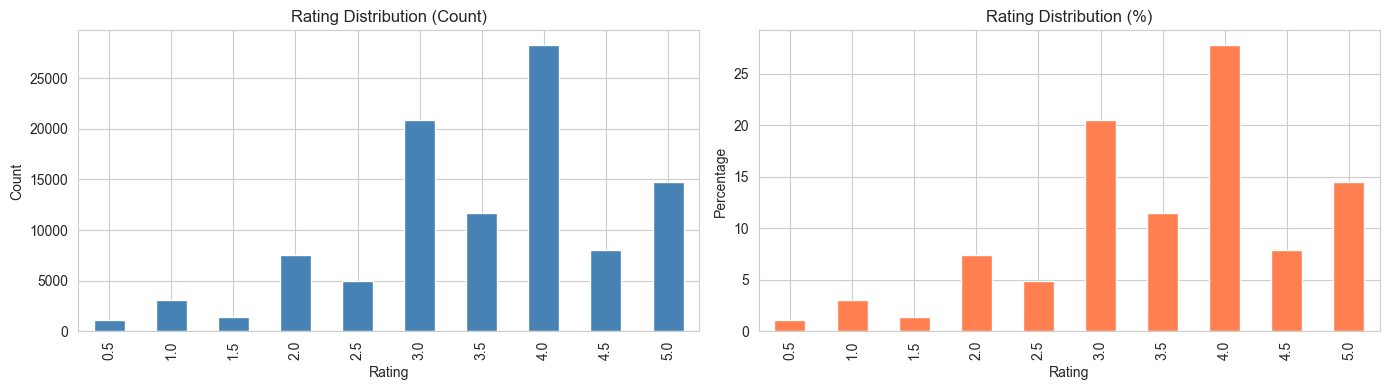


Most frequent rating : 4.0 (27.83%)
Least frequent rating: 0.5 (1.09%)
Imbalance ratio      : 25.53x

Conclusion: The target variable is IMBALANCED.
=> For classification models, use class_weight='balanced' or SMOTE.
=> Alternatively, consider Regression instead of Classification.


In [38]:
print("\n" + "=" * 60)
print("RATING BALANCE CHECK (Target Imbalance)")
print("=" * 60)

# Count and percentage per rating value
balance = (
    ratings['rating']
    .value_counts()
    .sort_index()
    .to_frame(name='count')
)
balance['percentage'] = (balance['count'] / len(ratings) * 100).round(2)
print(balance)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

balance['count'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Rating Distribution (Count)')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Count')

balance['percentage'].plot(kind='bar', ax=axes[1], color='coral')
axes[1].set_title('Rating Distribution (%)')
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Percentage')

plt.tight_layout()
plt.show()

# Balance ratio
max_pct = balance['percentage'].max()
min_pct = balance['percentage'].min()
print(f"\nMost frequent rating : {balance['percentage'].idxmax()} ({max_pct}%)")
print(f"Least frequent rating: {balance['percentage'].idxmin()} ({min_pct}%)")
print(f"Imbalance ratio      : {max_pct / min_pct:.2f}x")
print("\nConclusion: The target variable is IMBALANCED.")
print("=> For classification models, use class_weight='balanced' or SMOTE.")
print("=> Alternatively, consider Regression instead of Classification.")

Cell 7  — EDA: Sparsity & Long Tail


SPARSITY & LONG TAIL ANALYSIS
Users               : 668
Movies              : 6685
Ratings             : 101696
User-Item Matrix    : 668 x 6685 = 4,465,580 cells
Filled cells        : 101,696 (2.28%)
Sparsity            : 97.72%

=> A sparse matrix is normal for recommender systems.

--- Long Tail Analysis ---
Movies with < 5 ratings  : 2830
Movies with < 10 ratings : 4370
Top 10% movies hold      : 51.89% of all ratings


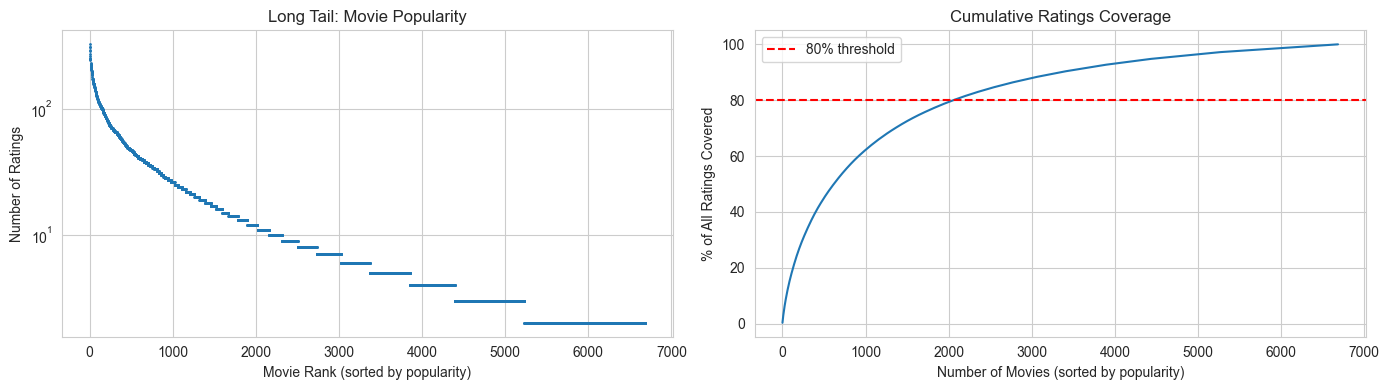

In [39]:
print("\n" + "=" * 60)
print("SPARSITY & LONG TAIL ANALYSIS")
print("=" * 60)

n_users = ratings['userId'].nunique()
n_movies = ratings['movieId'].nunique()
n_ratings = len(ratings)
sparsity = 1 - (n_ratings / (n_users * n_movies))

print(f"Users               : {n_users}")
print(f"Movies              : {n_movies}")
print(f"Ratings             : {n_ratings}")
print(f"User-Item Matrix    : {n_users} x {n_movies} = {n_users * n_movies:,} cells")
print(f"Filled cells        : {n_ratings:,} ({n_ratings / (n_users * n_movies) * 100:.2f}%)")
print(f"Sparsity            : {sparsity * 100:.2f}%")
print(f"\n=> A sparse matrix is normal for recommender systems.")

# Long Tail
movie_counts = ratings['movieId'].value_counts().sort_values(ascending=False)
top_10_pct_count = int(len(movie_counts) * 0.1)
top_10_pct_ratings = movie_counts.head(top_10_pct_count).sum()

print(f"\n--- Long Tail Analysis ---")
print(f"Movies with < 5 ratings  : {(movie_counts < 5).sum()}")
print(f"Movies with < 10 ratings : {(movie_counts < 10).sum()}")
print(f"Top 10% movies hold      : {top_10_pct_ratings / n_ratings * 100:.2f}% of all ratings")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(movie_counts.values, marker='.', linestyle='none', markersize=2)
axes[0].set_title('Long Tail: Movie Popularity')
axes[0].set_xlabel('Movie Rank (sorted by popularity)')
axes[0].set_ylabel('Number of Ratings')
axes[0].set_yscale('log')

axes[1].plot(movie_counts.values.cumsum() / n_ratings * 100)
axes[1].set_title('Cumulative Ratings Coverage')
axes[1].set_xlabel('Number of Movies (sorted by popularity)')
axes[1].set_ylabel('% of All Ratings Covered')
axes[1].axhline(y=80, color='red', linestyle='--', label='80% threshold')
axes[1].legend()

plt.tight_layout()
plt.show()

Cell 8  — EDA: Cold Start Analysis

In [40]:
print("\n" + "=" * 60)
print("COLD START ANALYSIS")
print("=" * 60)

user_counts = ratings['userId'].value_counts()
movie_counts = ratings['movieId'].value_counts()

# Users with few ratings
cold_users_5  = (user_counts < 5).sum()
cold_users_10 = (user_counts < 10).sum()
cold_users_20 = (user_counts < 20).sum()

# Movies with few ratings
cold_movies_5  = (movie_counts < 5).sum()
cold_movies_10 = (movie_counts < 10).sum()

print("Cold Users (few ratings):")
print(f"  < 5 ratings  : {cold_users_5:>4} users ({cold_users_5 / len(user_counts) * 100:.1f}%)")
print(f"  < 10 ratings : {cold_users_10:>4} users ({cold_users_10 / len(user_counts) * 100:.1f}%)")
print(f"  < 20 ratings : {cold_users_20:>4} users ({cold_users_20 / len(user_counts) * 100:.1f}%)")

print("\nCold Movies (few ratings):")
print(f"  < 5 ratings  : {cold_movies_5:>4} movies ({cold_movies_5 / len(movie_counts) * 100:.1f}%)")
print(f"  < 10 ratings : {cold_movies_10:>4} movies ({cold_movies_10 / len(movie_counts) * 100:.1f}%)")

# Power users
q1_u, q3_u = user_counts.quantile([0.25, 0.75])
iqr_u = q3_u - q1_u
power_users = user_counts[user_counts > q3_u + 1.5 * iqr_u]
print(f"\nPower users (IQR outliers): {len(power_users)} users")
print(f"  Holding {power_users.sum() / n_ratings * 100:.2f}% of all ratings")
print(f"  Max ratings by one user: {user_counts.max()}")

print("\n=> Cold start is a real challenge. Consider content-based fallback.")


COLD START ANALYSIS
Cold Users (few ratings):
  < 5 ratings  :    0 users (0.0%)
  < 10 ratings :    0 users (0.0%)
  < 20 ratings :    0 users (0.0%)

Cold Movies (few ratings):
  < 5 ratings  : 2830 movies (42.3%)
  < 10 ratings : 4370 movies (65.4%)

Power users (IQR outliers): 68 users
  Holding 48.38% of all ratings
  Max ratings by one user: 4111

=> Cold start is a real challenge. Consider content-based fallback.


Cell 9  — EDA: Genre Distribution


GENRE DISTRIBUTION
Number of movies per genre (a movie can have multiple genres):
             count  pct_of_movies
genres                           
Drama         3271          48.93
Comedy        2388          35.72
Thriller      1574          23.55
Action        1347          20.15
Romance       1207          18.06
Crime          980          14.66
Adventure      895          13.39
Sci-Fi         683          10.22
Horror         625           9.35
Fantasy        510           7.63
Mystery        462           6.91
Children       420           6.28
War            304           4.55
Animation      291           4.35
Musical        249           3.72
Documentary    182           2.72
IMAX           137           2.05
Western        136           2.03
Film-Noir       83           1.24


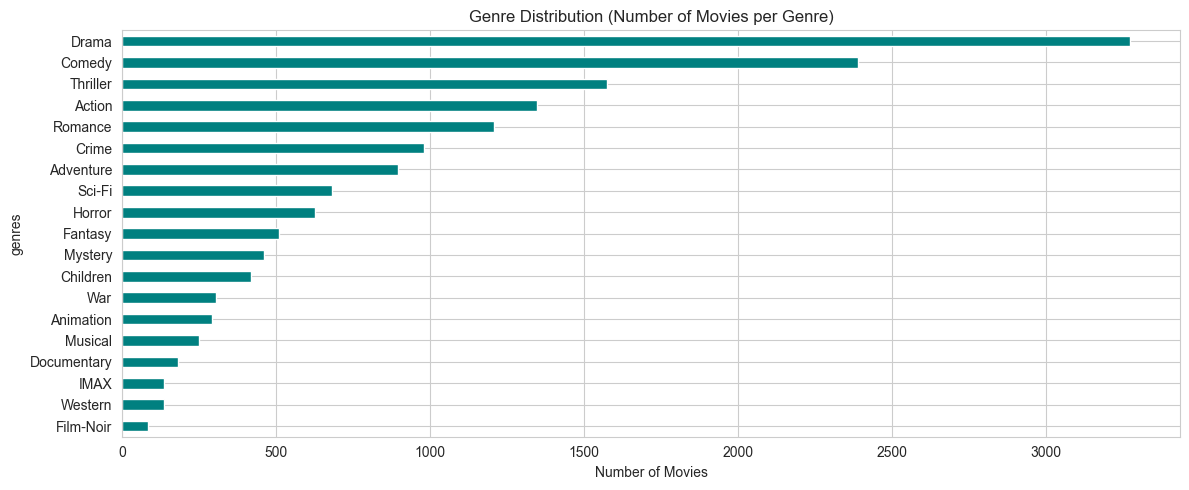


=> Genre distribution is IMBALANCED (Drama/Comedy dominate).


In [41]:
print("\n" + "=" * 60)
print("GENRE DISTRIBUTION")
print("=" * 60)

# Explode genres
movies_exploded = movies.copy()
movies_exploded['genres'] = movies_exploded['genres'].str.split('|')
movies_exploded = movies_exploded.explode('genres')

genre_counts = movies_exploded['genres'].value_counts()
genre_pct = (genre_counts / len(movies) * 100).round(2)

print("Number of movies per genre (a movie can have multiple genres):")
print(pd.DataFrame({'count': genre_counts, 'pct_of_movies': genre_pct}))

# Visualization
fig, ax = plt.subplots(figsize=(12, 5))
genre_counts.plot(kind='barh', ax=ax, color='teal')
ax.set_title('Genre Distribution (Number of Movies per Genre)')
ax.set_xlabel('Number of Movies')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print("\n=> Genre distribution is IMBALANCED (Drama/Comedy dominate).")

Cell جديدة — Top 10 Movies per Genre (Table + Plot)


In [51]:
# EDA: Top 10 Movies per Genre (Table + Plot)
print("TOP 10 MOVIES PER GENRE (min 50 ratings)")

# 1. Explode genres (movie can have multiple genres)
movies_exploded = movies.copy()
movies_exploded['genres'] = movies_exploded['genres'].str.split('|')
movies_exploded = movies_exploded.explode('genres')

# 2. Movie statistics
movie_stats_raw = (
    ratings.groupby('movieId')['rating']
    .agg(avg_rating='mean', num_ratings='count')
    .reset_index()
)

# 3. Merge
genre_movies = movies_exploded.merge(movie_stats_raw, on='movieId', how='left')

# 4. Filter: at least 50 ratings
MIN_RATINGS = 50
genre_movies = genre_movies[genre_movies['num_ratings'] >= MIN_RATINGS]

# 5. Top 10 per genre
top10 = (
    genre_movies
    .sort_values(['genres', 'avg_rating'], ascending=[True, False])
    .groupby('genres')
    .head(10)
    .reset_index(drop=True)
)

# 6. Print a clean table per genre
for genre in sorted(top10['genres'].unique()):
    subset = top10[top10['genres'] == genre].copy()
    subset['rank'] = range(1, len(subset) + 1)
    print(f"\n{'=' * 60}")
    print(f"  TOP 10 — {genre.upper()}")
    print(f"{'=' * 60}")
    print(subset[['rank', 'title', 'avg_rating', 'num_ratings']].to_string(index=False))

TOP 10 MOVIES PER GENRE (min 50 ratings)

  TOP 10 — ACTION
 rank                                                                          title  avg_rating  num_ratings
    1                                       Princess Mononoke (Mononoke-hime) (1997)    4.384615           52
    2                                                      North by Northwest (1959)    4.273973           73
    3                                                             Matrix, The (1999)    4.264368          261
    4                          Star Wars: Episode V - The Empire Strikes Back (1980)    4.228070          228
    5                                    Seven Samurai (Shichinin no samurai) (1954)    4.217742           62
    6 Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981)    4.212054          224
    7                                                               Inception (2010)    4.189320          103
    8                                      Star Wars: Episod

Cell جديدة — Plot لكل genre (barh)


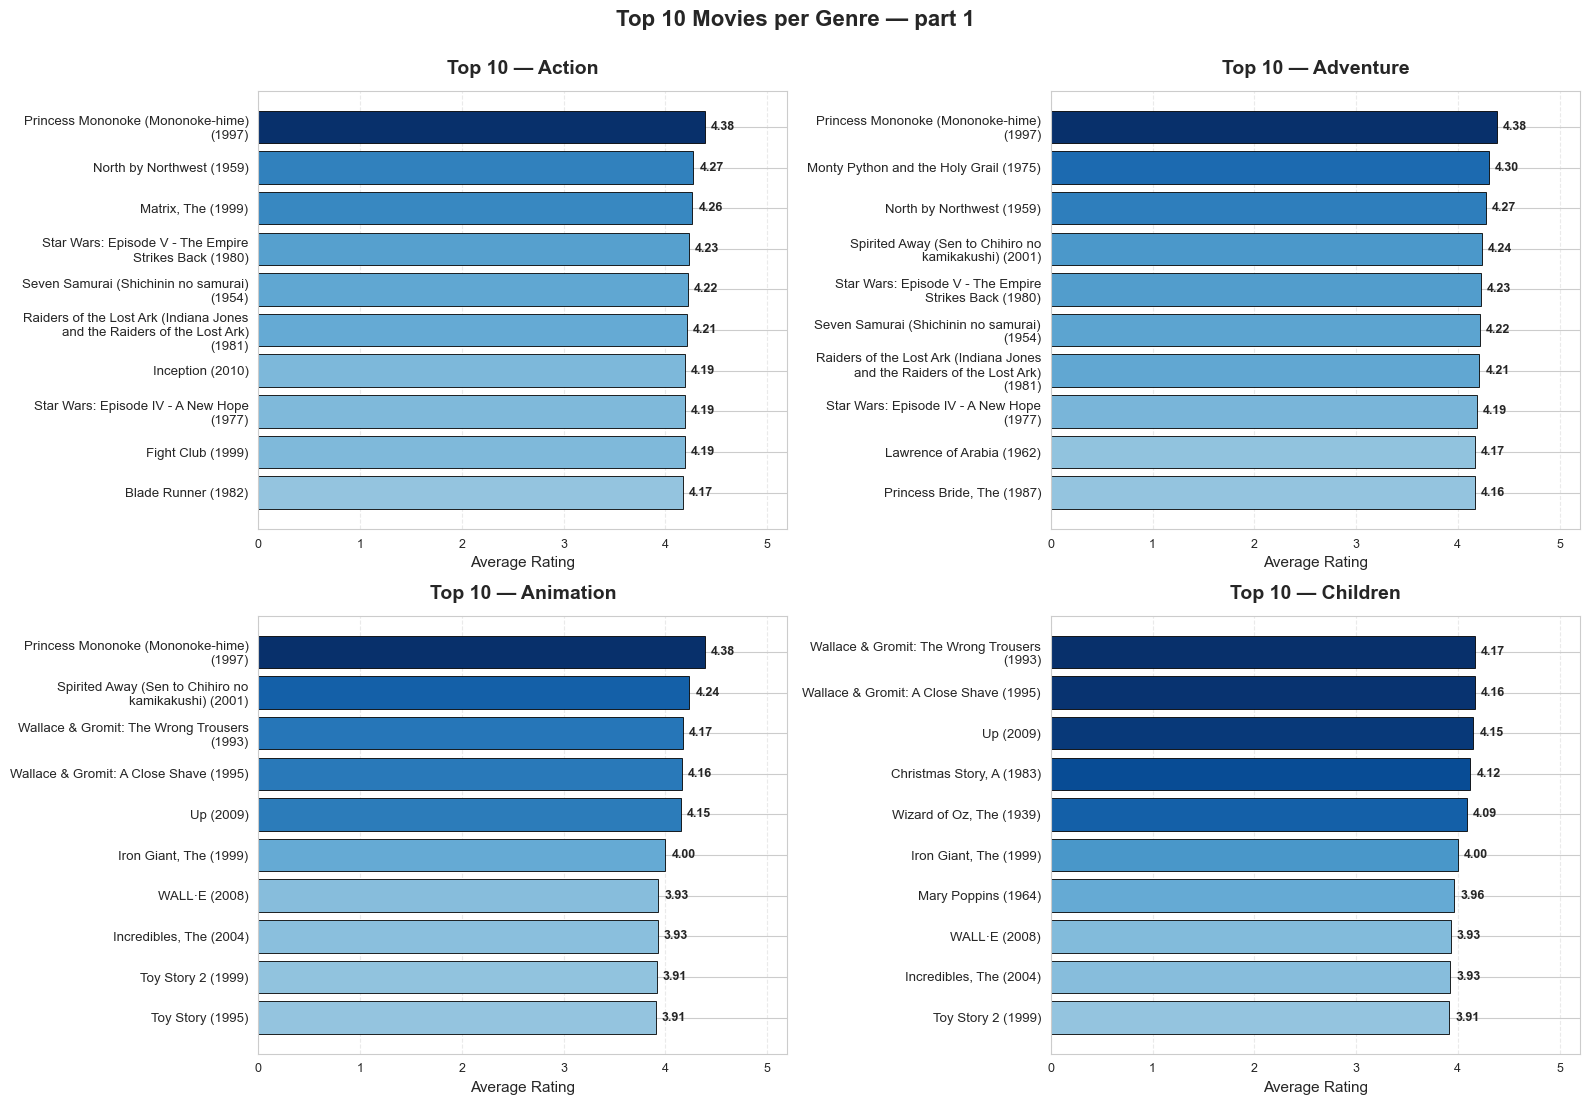

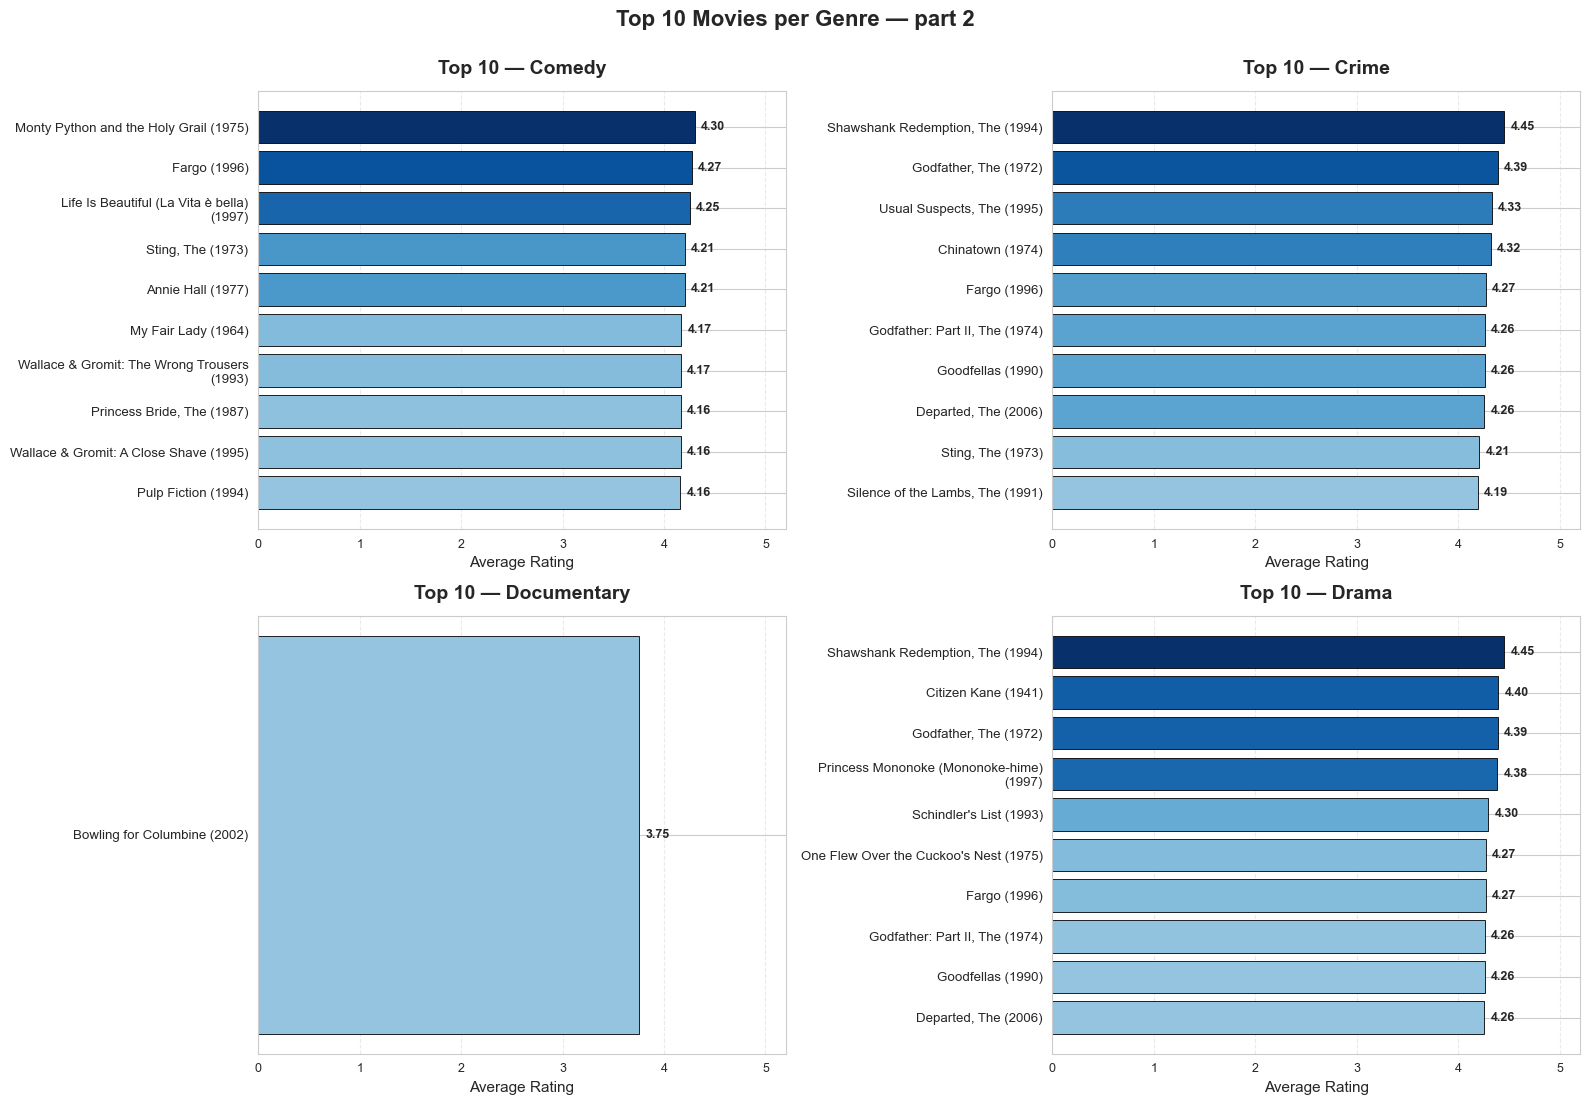

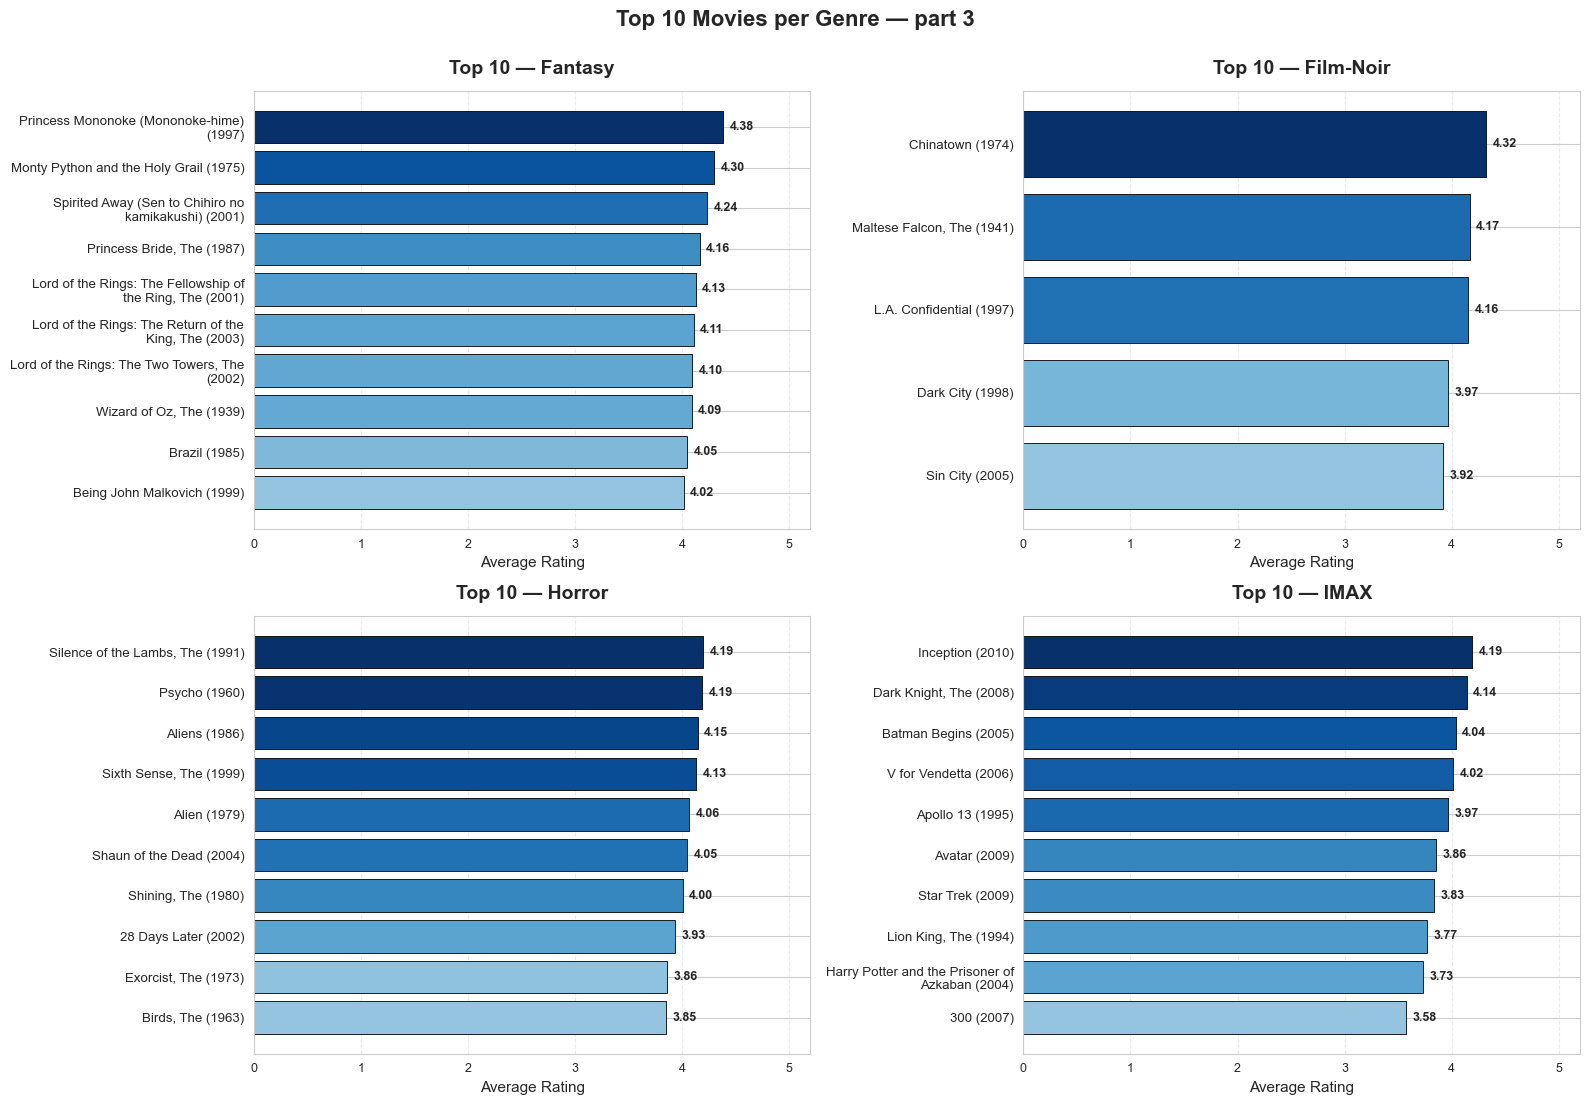

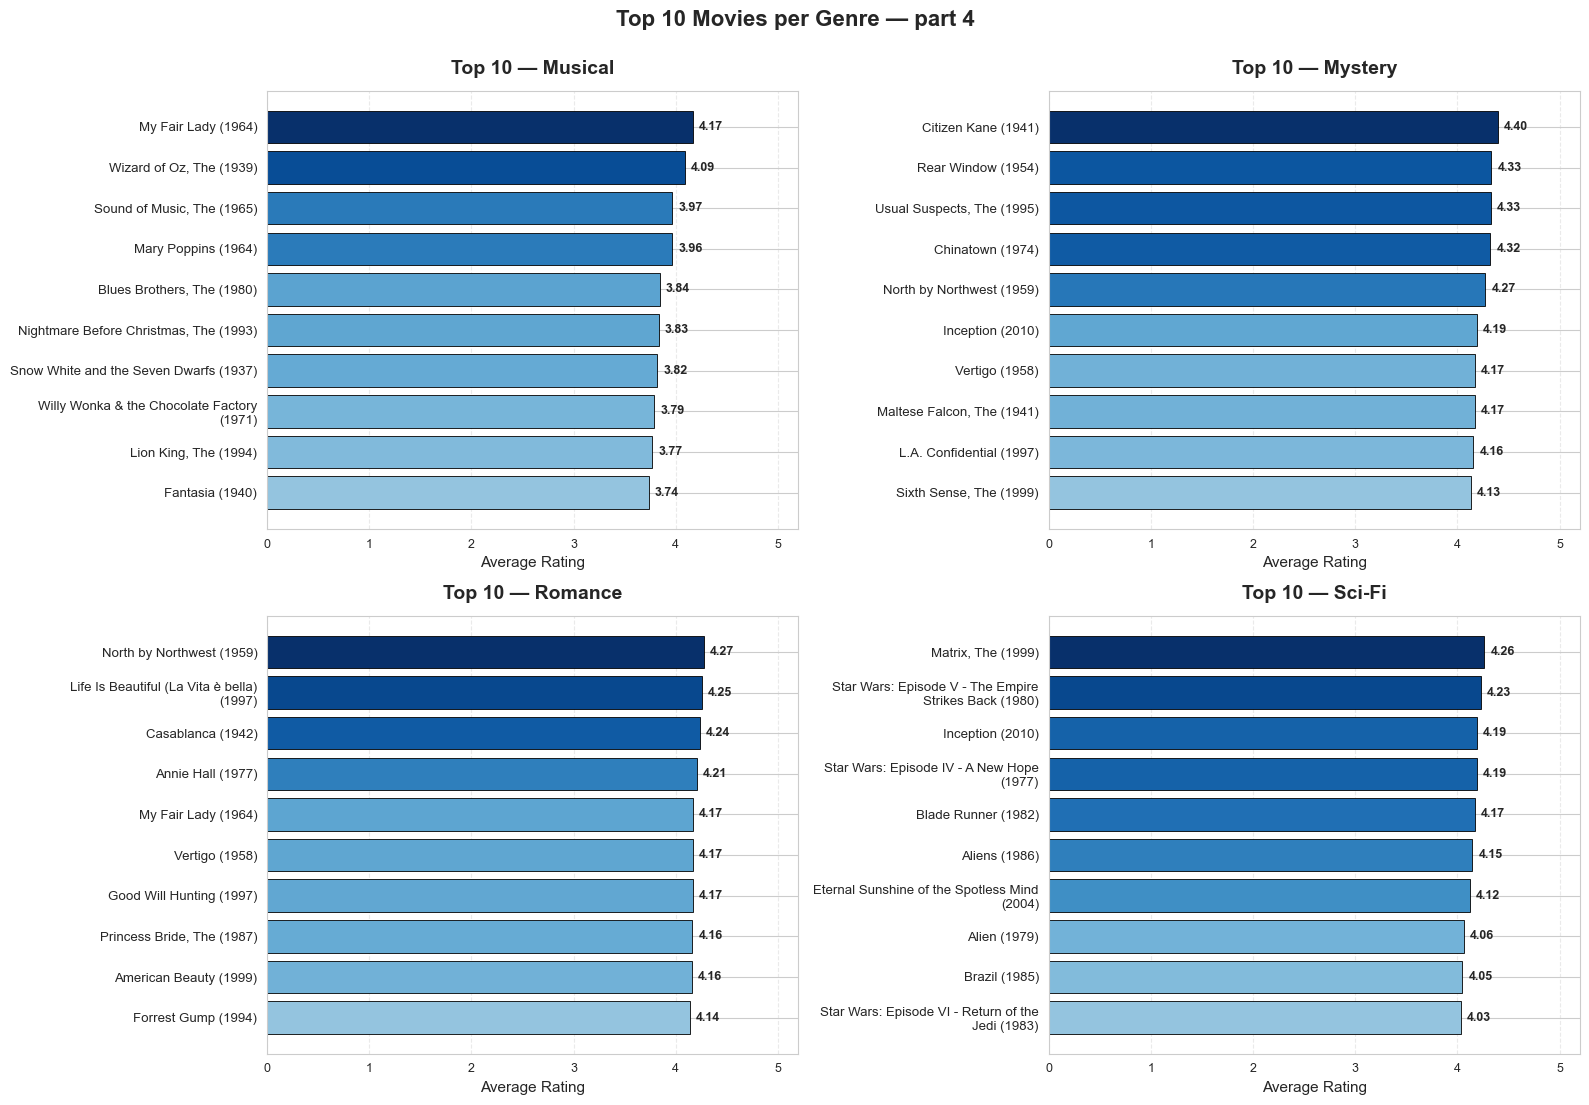

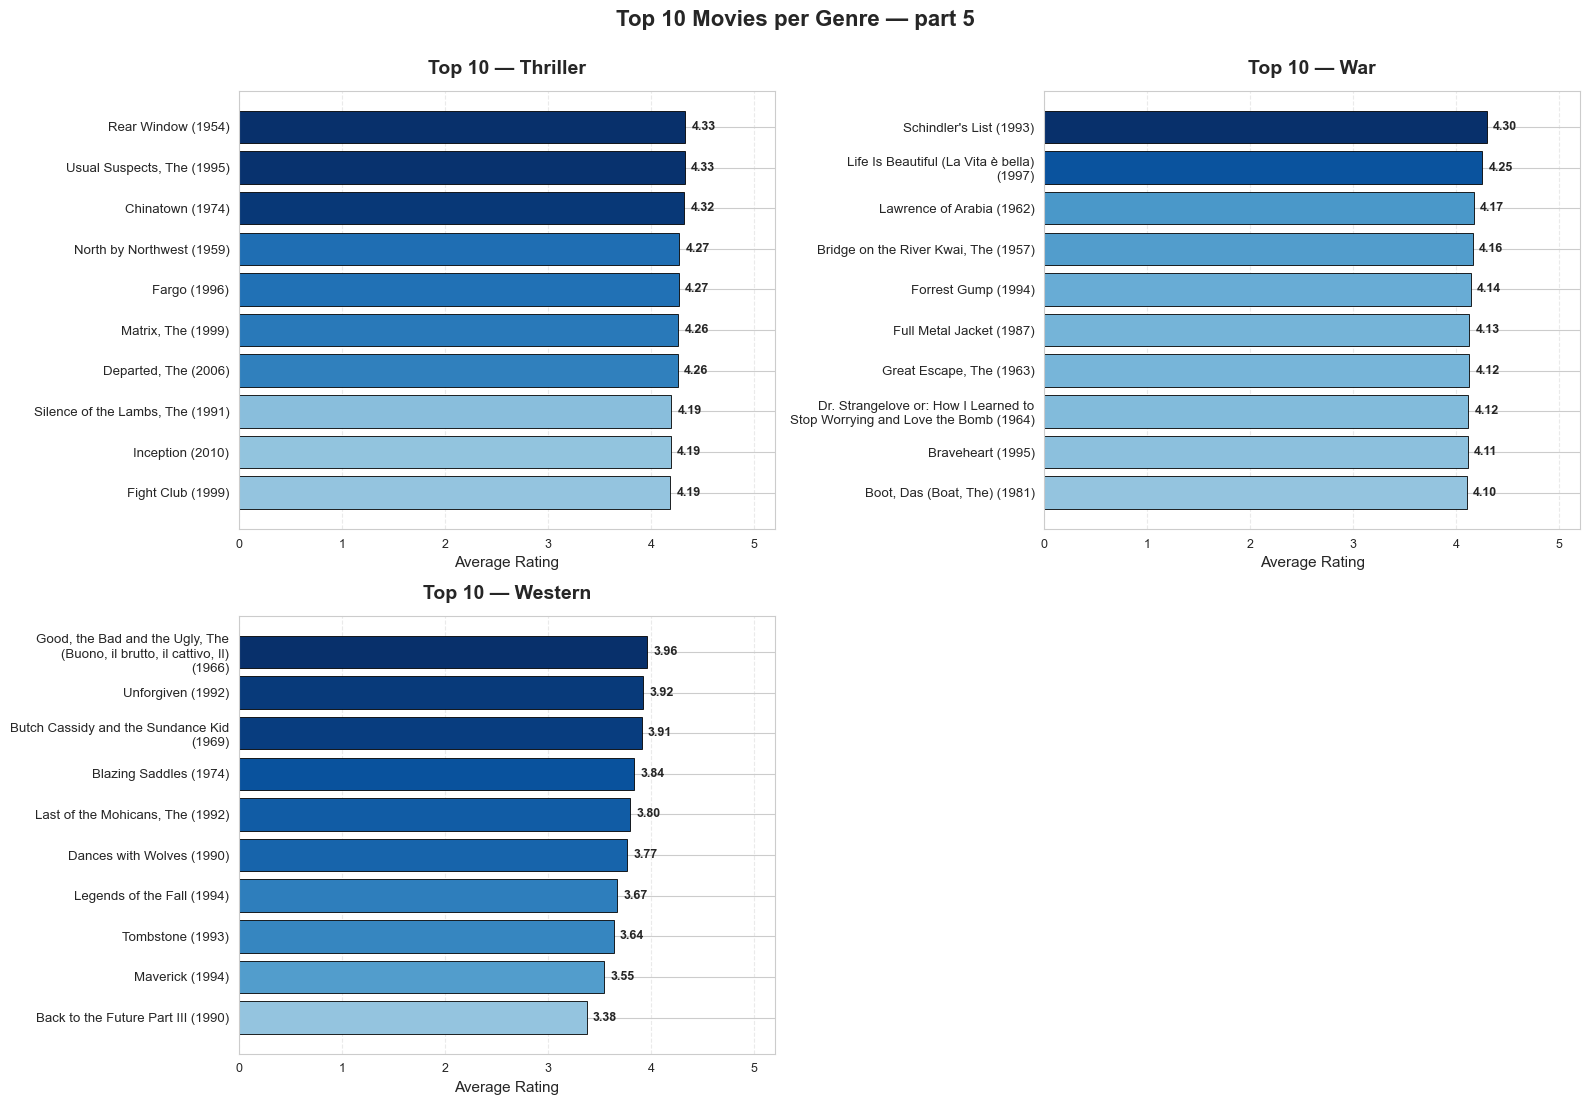

In [43]:
# ================================================================
# Plot: Top 10 Movies per Genre — Clear Layout (chunked)
# ================================================================
import textwrap

genres_list = sorted(top10['genres'].unique())
CHUNK_SIZE = 4   # 4 genres per figure (2 rows x 2 cols)

def shorten(title, width=40):
    """Wrap long titles into 2 lines for readability."""
    return "\n".join(textwrap.wrap(title, width=width))

for start in range(0, len(genres_list), CHUNK_SIZE):
    chunk = genres_list[start:start + CHUNK_SIZE]
    n_cols = 2
    n_rows = (len(chunk) + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 5.5 * n_rows))
    axes = axes.flatten() if n_rows * n_cols > 1 else [axes]

    for i, genre in enumerate(chunk):
        subset = (
            top10[top10['genres'] == genre]
            .sort_values('avg_rating', ascending=True)
        )
        labels = [shorten(t, width=38) for t in subset['title']]
        values = subset['avg_rating'].values

        # Color gradient: highest rating = darker
        colors = plt.cm.Blues(0.4 + 0.6 * (values - values.min()) /
                              (values.max() - values.min() + 1e-9))

        bars = axes[i].barh(labels, values, color=colors, edgecolor='black', linewidth=0.6)
        axes[i].set_title(f'Top 10 — {genre}', fontsize=14, fontweight='bold', pad=12)
        axes[i].set_xlabel('Average Rating', fontsize=11)
        axes[i].set_xlim(0, 5.2)
        axes[i].tick_params(axis='y', labelsize=9.5)
        axes[i].tick_params(axis='x', labelsize=9)
        axes[i].grid(axis='x', linestyle='--', alpha=0.4)
        axes[i].set_axisbelow(True)

        # Value labels at the end of each bar
        for bar, v in zip(bars, values):
            axes[i].text(
                v + 0.06, bar.get_y() + bar.get_height() / 2,
                f'{v:.2f}', va='center', fontsize=9, fontweight='bold'
            )

    # Hide unused subplots
    for k in range(len(chunk), len(axes)):
        axes[k].axis('off')

    plt.suptitle(
        f'Top 10 Movies per Genre — part {start // CHUNK_SIZE + 1}',
        fontsize=16, fontweight='bold', y=1.00
    )
    plt.tight_layout()
    plt.show()

Cell 10 — EDA: Top 10 Movies per Genre  

In [44]:
print("\n" + "=" * 60)
print("TOP 10 MOVIES PER GENRE (min 50 ratings)")
print("=" * 60)

# Reuse exploded movies + attach stats
movie_stats_raw = (
    ratings.groupby('movieId')['rating']
    .agg(avg_rating='mean', num_ratings='count')
    .reset_index()
)

genre_movies = movies_exploded.merge(movie_stats_raw, on='movieId', how='left')

# Filter: minimum number of ratings
MIN_RATINGS = 50
genre_movies_filtered = genre_movies[genre_movies['num_ratings'] >= MIN_RATINGS]

# Top 10 per genre
top10_per_genre = (
    genre_movies_filtered
    .sort_values(['genres', 'avg_rating'], ascending=[True, False])
    .groupby('genres')
    .head(10)
    .reset_index(drop=True)
)

# Print results
for genre in sorted(top10_per_genre['genres'].unique()):
    subset = top10_per_genre[top10_per_genre['genres'] == genre]
    print(f"\n--- Top 10: {genre} ---")
    print(subset[['title', 'avg_rating', 'num_ratings']].to_string(index=False))


TOP 10 MOVIES PER GENRE (min 50 ratings)

--- Top 10: Action ---
                                                                         title  avg_rating  num_ratings
                                      Princess Mononoke (Mononoke-hime) (1997)    4.384615           52
                                                     North by Northwest (1959)    4.273973           73
                                                            Matrix, The (1999)    4.264368          261
                         Star Wars: Episode V - The Empire Strikes Back (1980)    4.228070          228
                                   Seven Samurai (Shichinin no samurai) (1954)    4.217742           62
Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981)    4.212054          224
                                                              Inception (2010)    4.189320          103
                                     Star Wars: Episode IV - A New Hope (1977)    4.188645          27

Cell 11 — Feature Engineering: Genres One-Hot Encoding


In [45]:
print("\n" + "=" * 60)
print("FEATURE ENGINEERING")
print("=" * 60)

genres_dummies = movies['genres'].str.get_dummies(sep='|')
genres_dummies.columns = ['genre_' + c for c in genres_dummies.columns]
print(f"Genres one-hot encoded: {genres_dummies.shape[1]} genre columns")


FEATURE ENGINEERING
Genres one-hot encoded: 19 genre columns


Cell 12 — Feature Engineering: User & Movie Stats


In [46]:
user_stats = (
    ratings.groupby('userId')['rating']
    .agg(user_avg='mean', user_count='count')
    .reset_index()
)

movie_stats = (
    ratings.groupby('movieId')['rating']
    .agg(avg_rating='mean', num_ratings='count')
    .reset_index()
)

print(f"user_stats : {user_stats.shape}")
print(f"movie_stats: {movie_stats.shape}")

user_stats : (668, 3)
movie_stats: (6685, 3)


Cell 13 — Merge into Final Dataset


In [47]:
ratings_clean = ratings.merge(user_stats, on='userId', how='left')

movies_clean = pd.concat(
    [movies.reset_index(drop=True), genres_dummies.reset_index(drop=True)], axis=1
).merge(movie_stats, on='movieId', how='left')

final_df = ratings_clean.merge(movies_clean, on='movieId', how='left')

print(f"ratings_clean : {ratings_clean.shape}  | NaN: {ratings_clean.isnull().sum().sum()}")
print(f"movies_clean  : {movies_clean.shape}  | NaN: {movies_clean.isnull().sum().sum()}")
print(f"final_df      : {final_df.shape}  | NaN: {final_df.isnull().sum().sum()}")
display(final_df.head())

ratings_clean : (101696, 9)  | NaN: 0
movies_clean  : (6685, 25)  | NaN: 0
final_df      : (101696, 33)  | NaN: 0


,userId,movieId,rating,timestamp,year,month,is_reliable_movie,user_avg,user_count,title,genres,is_reliable,genre_Action,genre_Adventure,genre_Animation,genre_Children,genre_Comedy,genre_Crime,genre_Documentary,genre_Drama,genre_Fantasy,genre_Film-Noir,genre_Horror,genre_IMAX,genre_Musical,genre_Mystery,genre_Romance,genre_Sci-Fi,genre_Thriller,genre_War,genre_Western,avg_rating,num_ratings
0,1,16,4.0,2008-08-05 00:56:33,2008,8,True,3.638393,112,Casino (1995),Crime|Drama,True,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,3.785714,84
1,1,24,1.5,2008-08-05 00:23:27,2008,8,True,3.638393,112,Powder (1995),Drama|Sci-Fi,True,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,2.894737,38
2,1,32,4.0,2008-08-05 00:30:46,2008,8,True,3.638393,112,Twelve Monkeys (a.k.a. 12 Monkeys) (1995),Mystery|Sci-Fi|Thriller,True,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,3.939614,207
3,1,47,4.0,2008-08-05 00:35:56,2008,8,True,3.638393,112,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,True,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,4.130102,196
4,1,50,4.0,2008-08-05 00:35:23,2008,8,True,3.638393,112,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,True,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,4.328947,228


Cell 14 — Feature Selection & Save


In [48]:
# Drop columns not useful for modeling
final_df = final_df.drop(columns=['is_reliable_movie', 'is_reliable'], errors='ignore')

# Save the final dataset for Week 5 (Modeling)
final_df.to_csv(PROCESSED_DIR / 'final_df.csv', index=False)
movies_clean.to_csv(PROCESSED_DIR / 'movies_clean_features.csv', index=False)
print(f"final_df saved: {final_df.shape}")
print("Ready for Week 5 - Machine Learning")

final_df saved: (101696, 31)
Ready for Week 5 - Machine Learning
